# Demand model: how many bikes will leave and arrive at each station?
**Layer 1 of the predictor** (see Check-in 3). For every Divvy docking station and every hour, this notebook predicts
how many bikes will be **taken out** and how many will be **returned**. The app combines that forecast with the live bike count
to estimate the chance a station runs empty.

**Data:** Divvy trip history, June to October 2026, plus hourly Chicago weather from Open-Meteo.
**Test:** the model is trained on everything before the last 14 days and graded only on those 14 days, which it never sees.

**Run it:** In Colab, *Runtime > Run all*. It downloads everything itself (about 170 MB of zip files). Expect 5 to 15 minutes.

## 1. Setup

In [1]:
# Libraries: pandas/numpy for tables, scikit-learn for the model, matplotlib for charts, joblib to save the model.
import io, json, os, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

# Which months to train on. Divvy names files by year and month, e.g. 202610 = October 2026.
MONTHS = os.environ.get("TRIP_MONTHS", "202606,202607,202608,202609,202610").split(",")

# Repo root when run inside the repo (Actions, or a local clone); the current folder in Colab.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRIP_DIR = Path(os.environ.get("TRIP_DIR", ROOT / "trip_data"))
OUT = ROOT / "model" / "artifacts"
OUT.mkdir(parents=True, exist_ok=True)
TRIP_DIR.mkdir(parents=True, exist_ok=True)

# Chart style shared with the Check-in 2 notebook (colorblind-checked blue and orange).
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({"figure.figsize": (9, 4.2), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "xtick.color": MUTED, "ytick.color": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10})
print("scikit-learn", sklearn.__version__, "| months:", MONTHS)

scikit-learn 1.9.1 | months: ['202606', '202607', '202608', '202609', '202610']


## 2. Load trip history

In [2]:
# Download each month's zip from Divvy's public bucket once, then reuse the local copy.
# We only read the columns the model needs, which keeps memory low.
COLS = ["started_at", "ended_at", "start_station_name", "end_station_name"]

def load_month(m):
    csv_path = TRIP_DIR / f"{m}-divvy-tripdata.csv"
    if not csv_path.exists():
        url = f"https://divvy-tripdata.s3.amazonaws.com/{m}-divvy-tripdata.zip"
        raw = urllib.request.urlopen(url, timeout=300).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            name = next(n for n in z.namelist() if n.endswith(".csv") and not n.startswith("__MACOSX"))
            csv_path.write_bytes(z.read(name))
    return pd.read_csv(csv_path, usecols=COLS, parse_dates=["started_at", "ended_at"])

trips = pd.concat([load_month(m) for m in MONTHS], ignore_index=True)
print(f"{len(trips):,} trips loaded")

4,039,059 trips loaded


## 3. Clean
Rules carried over from Check-in 2:
- Drop trips under 1 minute (false starts) and over 24 hours (lost bikes, no real destination).
- Drop **Public Racks**, test and staff stations. Racks have no docks, so "empty" means nothing there, and they would make the model look better than it is.
- Keep only trips inside the months we asked for (each file also holds a few trips that started the month before).

In [3]:
minutes = (trips.ended_at - trips.started_at).dt.total_seconds() / 60
first_day = pd.Timestamp(f"{MONTHS[0][:4]}-{MONTHS[0][4:]}-01")
before = len(trips)
trips = trips[(minutes >= 1) & (minutes <= 1440) & (trips.started_at >= first_day)]
print(f"Removed {before - len(trips):,} trips by length or date")

def is_dock(name):
    s = name.fillna("")
    return ~s.str.contains("Public Rack|Test|STAFF|Warehouse|Hub", case=False) & (s != "")

dep_rows = trips[is_dock(trips.start_station_name)]
arr_rows = trips[is_dock(trips.end_station_name)]
print(f"{len(dep_rows):,} departures and {len(arr_rows):,} arrivals at docking stations")

Removed 103,072 trips by length or date


3,019,802 departures and 2,990,352 arrivals at docking stations


## 4. Station by hour table
One row per station per hour, counting bikes **taken out** (departures) and **returned** (arrivals).
Hours with no trips are real zeros, so we fill them in. Without them the model would never learn about quiet hours.

In [4]:
dep = dep_rows.groupby(["start_station_name", dep_rows.started_at.dt.floor("h")]).size()
arr = arr_rows.groupby(["end_station_name", arr_rows.ended_at.dt.floor("h")]).size()
dep.index.names = arr.index.names = ["station", "hour"]

# Keep stations with real activity (at least 1 trip a day on average) to avoid near-empty noise.
n_days = (trips.started_at.max() - first_day).days + 1
activity = dep.groupby("station").sum().add(arr.groupby("station").sum(), fill_value=0)
stations = activity[activity >= n_days].index
hours = pd.date_range(first_day, trips.started_at.max().floor("h"), freq="h")

panel = pd.MultiIndex.from_product([stations, hours], names=["station", "hour"]).to_frame(index=False)
panel = panel.merge(dep.rename("dep").reset_index(), how="left").merge(arr.rename("arr").reset_index(), how="left")
panel[["dep", "arr"]] = panel[["dep", "arr"]].fillna(0).astype("int16")
print(f"{len(stations):,} stations x {len(hours):,} hours = {len(panel):,} rows")

927 stations x 3,672 hours = 3,403,944 rows


## 5. Weather
Rain and cold cut riding (Check-in 2 found two rainy-day dips). We pull hourly temperature, rain and wind for Chicago from
[Open-Meteo](https://open-meteo.com/)'s historical archive. If the download fails, the notebook keeps going without weather,
and the model treats those columns as missing.

In [5]:
start, end = hours.min().date(), hours.max().date()
url = ("https://archive-api.open-meteo.com/v1/archive?latitude=41.95&longitude=-87.65"
       f"&start_date={start}&end_date={end}"
       "&hourly=temperature_2m,precipitation,wind_speed_10m&timezone=America%2FChicago")
try:
    w = json.load(urllib.request.urlopen(url, timeout=60))["hourly"]
    weather = pd.DataFrame({"hour": pd.to_datetime(w["time"]), "temp_c": w["temperature_2m"],
                            "precip_mm": w["precipitation"], "wind_kmh": w["wind_speed_10m"]})
    print(f"Weather: {len(weather):,} hours, {weather.precip_mm.gt(0).mean():.1%} of hours with rain")
except Exception as e:
    print("Weather download failed, continuing without it:", e)
    weather = pd.DataFrame({"hour": hours, "temp_c": np.nan, "precip_mm": np.nan, "wind_kmh": np.nan})
panel = panel.merge(weather, on="hour", how="left")

Weather: 3,672 hours, 19.4% of hours with rain


## 6. Features
Every feature must be **known at the moment the app makes a prediction**. That rules out "trips in the last hour": the live feed
shows how many bikes a station has, not how many people took one out. So the model uses:
- **Calendar:** hour, day of week, weekend, holiday.
- **Weather:** temperature, rain, wind (from a forecast when the app runs live).
- **Station habits:** each station's average departures and arrivals for that hour on weekdays vs weekends, learned from the training period only.

In [6]:
HOLIDAYS = pd.to_datetime(["2026-06-19", "2026-07-03", "2026-07-04", "2026-09-07", "2026-10-12",
                           "2026-11-26", "2026-11-27", "2026-12-25"])
panel["h"] = panel.hour.dt.hour.astype("int8")
panel["dow"] = panel.hour.dt.dayofweek.astype("int8")
panel["weekend"] = (panel.dow >= 5).astype("int8")
panel["holiday"] = panel.hour.dt.normalize().isin(HOLIDAYS).astype("int8")
panel["day_type"] = np.where((panel.weekend == 1) | (panel.holiday == 1), "off", "work")

# Time-based split: the last 14 days are the test set. Never a random split, which would leak the future.
SPLIT = hours.max().normalize() - pd.Timedelta(days=13)
train_mask = panel.hour < SPLIT
print(f"Train: {first_day.date()} to {(SPLIT - pd.Timedelta(days=1)).date()} | Test: {SPLIT.date()} to {hours.max().date()}")

# Station habits from TRAINING rows only, so the test period stays unseen.
profile = (panel[train_mask].groupby(["station", "h", "day_type"])
           .agg(dep_avg=("dep", "mean"), arr_avg=("arr", "mean")).reset_index())
panel = panel.merge(profile, on=["station", "h", "day_type"], how="left")
panel[["dep_avg", "arr_avg"]] = panel[["dep_avg", "arr_avg"]].fillna(0)

FEATURES = ["h", "dow", "weekend", "holiday", "temp_c", "precip_mm", "wind_kmh", "dep_avg", "arr_avg"]
# Drop any feature with no data at all (e.g. weather when its download failed): the model cannot learn from an empty column.
FEATURES = [f for f in FEATURES if panel[f].notna().any()]
print("Features:", FEATURES)
train, test = panel[train_mask], panel[~train_mask]
print(f"{len(train):,} training rows, {len(test):,} test rows")

Train: 2026-06-01 to 2026-10-17 | Test: 2026-10-18 to 2026-10-31


Features: ['h', 'dow', 'weekend', 'holiday', 'temp_c', 'precip_mm', 'wind_kmh', 'dep_avg', 'arr_avg']
3,092,472 training rows, 311,472 test rows


## 7. Train and test
Gradient-boosted trees with a **Poisson** loss, the standard choice for counts (0, 1, 2, ... bikes).
We grade on the 14 held-out days against two simple rules the model must beat:
- **Station habit:** predict the station's usual average for that hour and day type.
- **Zero:** predict no bikes move (most station-hours are quiet, so this is harder to beat than it sounds).

In [7]:
models, preds = {}, {}
for target in ["dep", "arr"]:
    m = HistGradientBoostingRegressor(loss="poisson", max_iter=400, learning_rate=0.06,
                                      max_leaf_nodes=63, random_state=0)
    m.fit(train[FEATURES], train[target])
    models[target], preds[target] = m, m.predict(test[FEATURES])

busy = (test.dep_avg + test.arr_avg) >= 2  # station-hours that normally see 2+ bikes move
rows = []
for target, name in [("dep", "Bikes leaving"), ("arr", "Bikes arriving")]:
    y, p, base = test[target], preds[target], test[f"{target}_avg"]
    rows.append({"prediction": name, "stations": "all",
                 "model_MAE": mean_absolute_error(y, p), "habit_MAE": mean_absolute_error(y, base),
                 "zero_MAE": mean_absolute_error(y, 0 * p)})
    rows.append({"prediction": name, "stations": "busy hours",
                 "model_MAE": mean_absolute_error(y[busy], p[busy]), "habit_MAE": mean_absolute_error(y[busy], base[busy]),
                 "zero_MAE": mean_absolute_error(y[busy], 0 * p[busy])})
results = pd.DataFrame(rows)
results["model_vs_habit_%"] = ((1 - results.model_MAE / results.habit_MAE) * 100).round(1)
results.round(3)

,prediction,stations,model_MAE,habit_MAE,zero_MAE,model_vs_habit_%
0,Bikes leaving,all,0.617,0.635,0.808,2.9
1,Bikes leaving,busy hours,1.529,1.590,2.459,3.8
2,Bikes arriving,all,0.597,0.618,0.797,3.3
3,Bikes arriving,busy hours,1.491,1.556,2.457,4.2


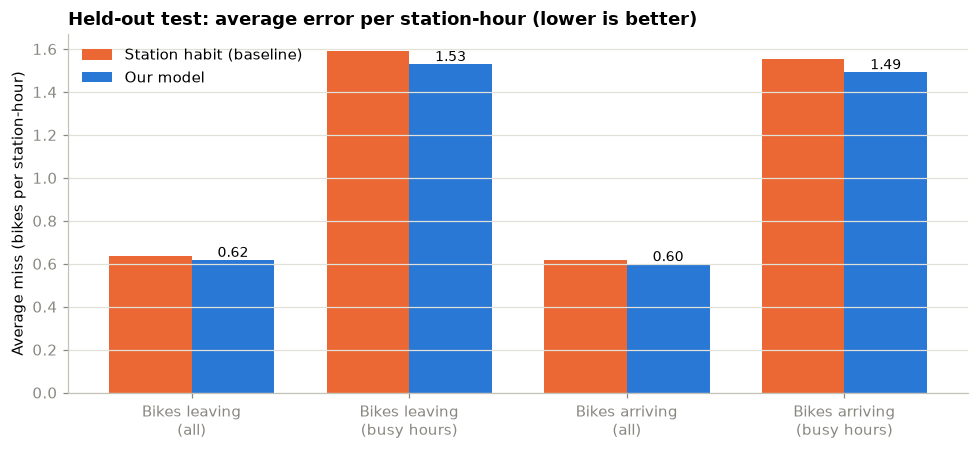

In [8]:
# Chart: error by method. Lower is better.
fig, ax = plt.subplots()
labels = [f"{r.prediction}\n({r.stations})" for r in results.itertuples()]
x = np.arange(len(results)); w = 0.38
ax.bar(x - w/2, results.habit_MAE, w, color=ORANGE, label="Station habit (baseline)")
ax.bar(x + w/2, results.model_MAE, w, color=BLUE, label="Our model")
for i, r in enumerate(results.itertuples()):
    ax.text(i + w/2, r.model_MAE, f"{r.model_MAE:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylabel("Average miss (bikes per station-hour)")
ax.set_title("Held-out test: average error per station-hour (lower is better)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### What the model leans on

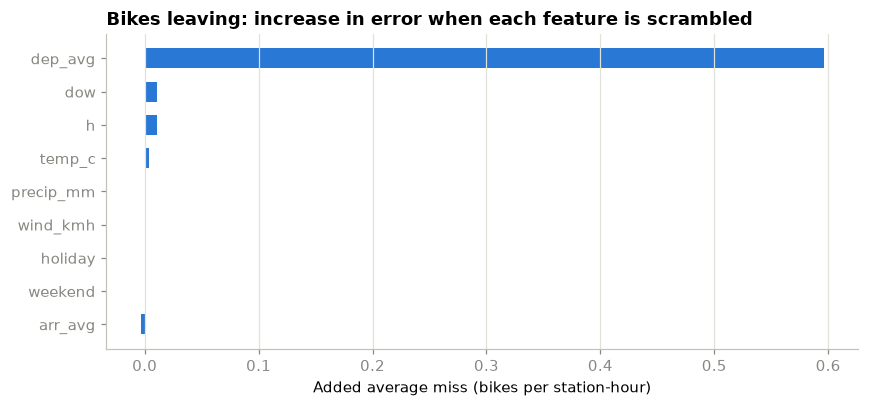

In [9]:
# Permutation importance: shuffle one feature at a time and measure how much worse predictions get.
sample = test.sample(min(200_000, len(test)), random_state=0)
imp = permutation_importance(models["dep"], sample[FEATURES], sample["dep"],
                             scoring="neg_mean_absolute_error", n_repeats=3, random_state=0)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Bikes leaving: increase in error when each feature is scrambled")
ax.set_xlabel("Added average miss (bikes per station-hour)")
plt.tight_layout(); plt.show()

### One Loyola station, test period

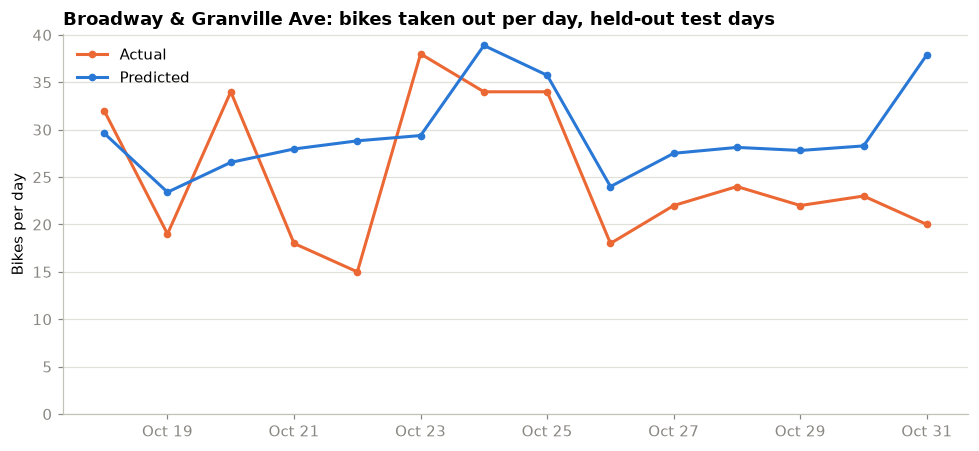

Test period total: actual 353, predicted 414


In [10]:
# Broadway & Granville is the busiest station near Loyola (Check-in 2, Q1).
STATION = "Broadway & Granville Ave"
if STATION in set(test.station):
    s = test[test.station == STATION].assign(pred=preds["dep"][(test.station == STATION).values])
    daily = s.set_index("hour")[["dep", "pred"]].resample("D").sum()
    fig, ax = plt.subplots()
    ax.plot(daily.index, daily.dep, color=ORANGE, lw=2, marker="o", ms=4, label="Actual")
    ax.plot(daily.index, daily.pred, color=BLUE, lw=2, marker="o", ms=4, label="Predicted")
    ax.set_title(f"{STATION}: bikes taken out per day, held-out test days")
    ax.set_ylabel("Bikes per day"); ax.set_ylim(0, None); ax.legend(frameon=False)
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    plt.tight_layout(); plt.show()
    print(f"Test period total: actual {int(daily.dep.sum())}, predicted {daily.pred.sum():.0f}")
else:
    print(STATION, "not in this data")

## 8. Save for the app
The app loads these files instead of retraining. The model is retrained on the **full** period first, so the live version uses
every day we have, not just the training slice. Its test score above is the honest estimate of how it will do.

In [11]:
full_profile = (panel.groupby(["station", "h", "day_type"])
                .agg(dep_avg=("dep", "mean"), arr_avg=("arr", "mean")).reset_index())
panel_full = panel.drop(columns=["dep_avg", "arr_avg"]).merge(full_profile, on=["station", "h", "day_type"], how="left")
for target in ["dep", "arr"]:
    m = HistGradientBoostingRegressor(loss="poisson", max_iter=400, learning_rate=0.06,
                                      max_leaf_nodes=63, random_state=0)
    m.fit(panel_full[FEATURES], panel_full[target])
    joblib.dump(m, OUT / f"demand_{target}.joblib")
full_profile.round(4).to_csv(OUT / "station_profile.csv.gz", index=False)

meta = {"trained_on_months": MONTHS, "test_start": str(SPLIT.date()), "test_end": str(hours.max().date()),
        "features": FEATURES, "sklearn_version": sklearn.__version__, "stations": int(len(stations)),
        "weather_used": bool(weather.temp_c.notna().any()),
        "results": results.round(4).to_dict(orient="records")}
(OUT / "demand_meta.json").write_text(json.dumps(meta, indent=2))
print("Saved to", OUT)
print(json.dumps(meta, indent=2)[:1500])

Saved to /home/runner/work/divvy-loyola/divvy-loyola/model/artifacts
{
  "trained_on_months": [
    "202606",
    "202607",
    "202608",
    "202609",
    "202610"
  ],
  "test_start": "2026-10-18",
  "test_end": "2026-10-31",
  "features": [
    "h",
    "dow",
    "weekend",
    "holiday",
    "temp_c",
    "precip_mm",
    "wind_kmh",
    "dep_avg",
    "arr_avg"
  ],
  "sklearn_version": "1.9.1",
  "stations": 927,
  "weather_used": true,
  "results": [
    {
      "prediction": "Bikes leaving",
      "stations": "all",
      "model_MAE": 0.6168,
      "habit_MAE": 0.6354,
      "zero_MAE": 0.8084,
      "model_vs_habit_%": 2.9
    },
    {
      "prediction": "Bikes leaving",
      "stations": "busy hours",
      "model_MAE": 1.5287,
      "habit_MAE": 1.5897,
      "zero_MAE": 2.4587,
      "model_vs_habit_%": 3.8
    },
    {
      "prediction": "Bikes arriving",
      "stations": "all",
      "model_MAE": 0.5971,
      "habit_MAE": 0.6178,
      "zero_MAE": 0.7975,
      "mode

## What this means
- The model's job is the **flow** of bikes; the live feed supplies the **stock** (bikes there now). Layer 3 combines them.
- Check the table: if the model does not beat the station-habit baseline on held-out days, that is a finding to report, not hide.
- Limits: trained on June to October, but the app runs in November and December, when riding is lower. Weather and the
  station-habit features carry most of the seasonal signal; Layer 3, trained on our November snapshots, corrects the rest.